# Signals: when is a day unusual?

**Nicholas Soulakis, PhD** · October 2026

**Summary.** A case definition counts cases; surveillance asks whether a day's count is unusual for its recent past. This notebook builds daily series for burns and head injuries among adults (NEISS), checks them, applies an EARS-style detector, sets its threshold from a stated workload, and shows how a flag is investigated. It is a **retrospective** analysis of published data: it shows how the method behaves on past days, not what an analyst would have seen in real time.

*Adapted from Methods in Health and Biomedical Informatics, taught by the author as HSIP 441 at Northwestern University Feinberg School of Medicine and MSBI 33100 at the University of Chicago. Python implementation, 2026.*

## Why it matters

Every surveillance system decides what counts as "more than usual" before anyone picks up the phone. Too sensitive and staff chase noise; too dull and real clusters slip by. Here the threshold is set from a workload: about one flag per 100 days for each series.

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("../utils").exists():
    os.system("git clone -q https://github.com/nsoulakis/public_health_surveillance")
    os.chdir("public_health_surveillance/python/notebooks")
sys.path.insert(0, "..")

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from utils import neiss, signals
from utils.settings import CALIBRATION, EVALUATION, TARGET_RATE, WINDOW

df = neiss.adults(neiss.code_cases(neiss.read_years()))
start, end = df["trmt_date"].min(), df["trmt_date"].max()
daily = {d: signals.daily_series(df, d, start, end) for d in neiss.DEFINITIONS}
print(f"Adults, {start.date()} to {end.date()}: {len(df):,} sampled visits, one row per calendar day")

Adults, 2014-01-01 to 2025-12-31: 2,435,187 sampled visits, one row per calendar day


## Two measures, two questions

- **Count:** sampled adult visits that are cases. It answers "how much work arrived?" It is a sample count, not an incidence, and it moves with the number of reporting hospitals.
- **Ratio:** weighted cases divided by weighted non-cases (classified visits only). It answers "did the mix change?" Busy days for every kind of injury raise the count but not the ratio. It is a ratio of weighted totals used as a signal, with no population claim.¹

A practitioner reads both.

¹ The ratio is Nicholas Soulakis's `ratio_to_other`; EARS methods apply to counts or to a share of visits with a non-syndrome denominator (Hutwagner et al., *Stat Med* 2005;24:543–550).

## Check the series

Before detection: weekday pattern, days with an undefined ratio, and changes in recording across years.

In [3]:
checks = []
for d, s in daily.items():
    by_weekday = s["count"].groupby(s.index.dayofweek).mean().round(1)
    checks.append({"definition": d,
                   "undefined_ratio_days": int(s["ratio"].isna().sum()),
                   "mean_count_mon_to_sun": list(by_weekday)})
pd.DataFrame(checks)

,definition,undefined_ratio_days,mean_count_mon_to_sun
0,burn,0,"[9.1, 8.6, 8.5, 8.3, 8.2, 9.4, 10.1]"
1,head_injury,0,"[95.7, 91.7, 91.3, 91.1, 91.8, 94.2, 93.0]"


In [4]:
yearly = pd.DataFrame({d: s["count"].groupby(s.index.year).mean().round(1) for d, s in daily.items()})
yearly.index.name = "year (mean daily count)"
yearly

,burn,head_injury
year (mean daily count),,
2014,8.9,74.8
2015,8.9,75.2
2016,9.1,77.8
2017,9.2,81.4
2018,8.5,82.1
2019,8.8,94.7
2020,8.6,86.7
2021,8.8,97.2
2022,8.1,97.1


## The method

For each day *t*, with the mean μ and standard deviation σ of the previous 14 days (*t*−14 to *t*−1):

**flag when** value(*t*) > μ + *k*·σ

This is the structure of CDC's EARS C1 (Hutwagner et al., *Stat Med* 2005 and *Emerg Infect Dis* 2005;11:314–316), which uses 7 days; this analysis uses 14, as in the author's original course program (PHI_040). The first 14 days have no full baseline and are not scored.

*k* is backed into for each series so that the calibration years give one flag per 100 days, then frozen and applied unchanged to later years (an empirical alert rate, as in Jackson et al., *BMC Med Inform Decis Mak* 2007;7:6). The rates below are **alert rates**: with no record of which days were true events, they are not specificity or false-alarm rates.

In [5]:
series = {(d, m): daily[d][m] for d in neiss.DEFINITIONS for m in ["count", "ratio"]}
k = {key: signals.calibrate_k(s, *CALIBRATION) for key, s in series.items()}
results = {key: signals.ears_c1(s, k[key]) for key, s in series.items()}
pd.DataFrame([{"definition": d, "measure": m, "k": k[(d, m)],
               "days_sd_zero": int(results[(d, m)]["sd_zero"].sum())} for d, m in series])

,definition,measure,k,days_sd_zero
0,burn,count,3.06,0
1,burn,ratio,3.47,0
2,head_injury,count,2.80,0
3,head_injury,ratio,2.91,0


In [6]:
periods = {f"calibration {CALIBRATION[0][:4]}-{CALIBRATION[1][:4]}": CALIBRATION,
           f"evaluation {EVALUATION[0][:4]}-{EVALUATION[1][:4]}": EVALUATION}
named = {f"{d} {m}": r for (d, m), r in results.items()}
signals.alert_summary(named, periods)

,period,series,days,flags,per_100_days
0,calibration 2014-2018,burn count,1812,19,1.05
1,calibration 2014-2018,burn ratio,1812,19,1.05
2,calibration 2014-2018,head_injury count,1812,19,1.05
3,calibration 2014-2018,head_injury ratio,1812,18,0.99
4,calibration 2014-2018,any series (combined workload),1812,65,3.59
5,evaluation 2019-2025,burn count,2557,33,1.29
6,evaluation 2019-2025,burn ratio,2557,27,1.06
7,evaluation 2019-2025,head_injury count,2557,34,1.33
8,evaluation 2019-2025,head_injury ratio,2557,27,1.06
9,evaluation 2019-2025,any series (combined workload),2557,97,3.79


The combined row is the workload an analyst watching all four series would face: days on which at least one series flags. The evaluation years include the year NEISS began filling the second diagnosis and body part (see the case-definition notebook); the 14-day baseline absorbs that step within two weeks, but the alert rate across the change is reported, not adjusted.

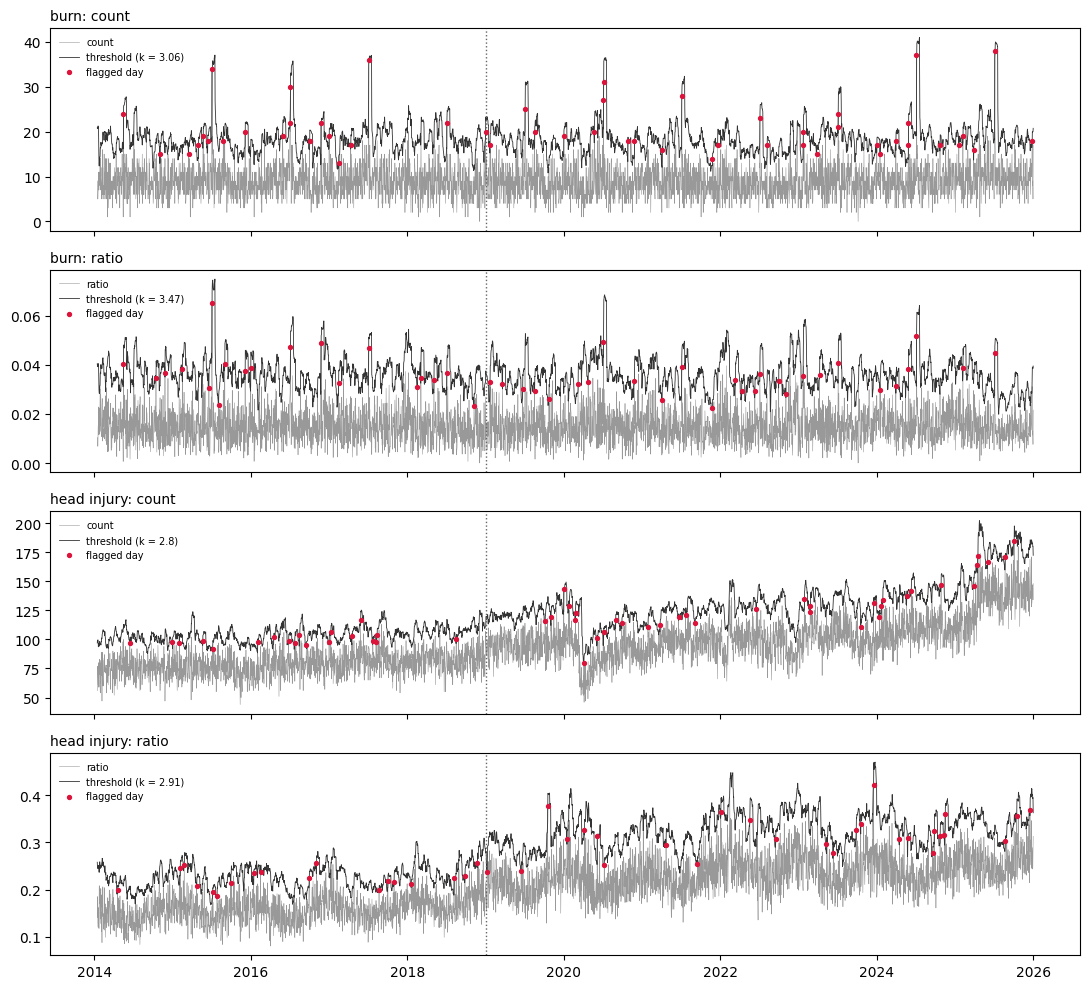

In [7]:
fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
for ax, ((d, m), r) in zip(axes, results.items()):
    ax.plot(r.index, r["value"], lw=0.4, color="0.6", label=m)
    ax.plot(r.index, r["threshold"], lw=0.6, color="0.2", label=f"threshold (k = {k[(d, m)]})")
    f = r[r["flag"]]
    ax.scatter(f.index, f["value"], color="crimson", s=8, zorder=3, label="flagged day")
    ax.axvline(pd.Timestamp(EVALUATION[0]), color="0.4", ls=":", lw=1)
    ax.set_title(f"{d.replace('_', ' ')}: {m}", loc="left", fontsize=10)
    ax.legend(loc="upper left", frameon=False, fontsize=7)
fig.tight_layout()

## Investigating a flag

A flag is a question. The investigation starts descriptive: the flagged day's cases, set against the 14 baseline days, by person, place and time.² The example uses the largest flagged value in the burn count series (the rule in PHI_040).

² After Heffernan et al., *Emerg Infect Dis* 2004;10:858–864 (signal response: line list, then stepwise follow-up).

In [8]:
CASE_STUDY = {"settings": (14, 0.01, ("2014-01-01", "2018-12-31")), "day": "2025-07-04"}
case = "burn"
day = signals.top_flag(results[(case, "count")])
if (WINDOW, TARGET_RATE, CALIBRATION) != CASE_STUDY["settings"] or str(day.date()) != CASE_STUDY["day"]:
    print("This run differs from the default: the written case study below describes "
          f"{CASE_STUDY['day']} under the default settings, not this result.")
full = neiss.adults(neiss.code_cases(neiss.read_year(day.year)))
window = full[(full["trmt_date"] >= day - pd.Timedelta(days=WINDOW)) & (full["trmt_date"] <= day)]
cases = window[window[case] == 1]
on_day = cases[cases["trmt_date"] == day]
assert len(on_day) == daily[case].loc[day, "count"], "line list does not match the daily count"
r = results[(case, "count")].loc[day]
print(f"{day.date()}: {len(on_day)} sampled burn visits; baseline mean {r['mean']:.1f}, SD {r['sd']:.1f}, threshold {r['threshold']:.1f}")

2025-07-04: 38 sampled burn visits; baseline mean 9.0, SD 3.0, threshold 18.1


In [9]:
formats = neiss.read_formats()
base = cases[cases["trmt_date"] < day]

def compare(col, top=6):
    lab_day = neiss.label(on_day[[col]], formats)[col].value_counts()
    lab_base = neiss.label(base[[col]], formats)[col].value_counts() / WINDOW
    out = pd.DataFrame({"flag_day": lab_day, "baseline_per_day": lab_base.round(1)}).fillna(0)
    return out.sort_values("flag_day", ascending=False).head(top)

compare("prod1")

,flag_day,baseline_per_day
prod1,,
1313 - FIREWORKS,12.0,0.2
"3249 - GRILLS, NOT SPECIFIED",7.0,0.2
1934 - HOT WATER,3.0,1.3
"466 - COOKWARE, NOT SPECIFIED",3.0,0.9
3248 - GAS OR LP GRILLS OR STOVES (FOR OUTDOOR USE),2.0,0.3
1604 - CIGARETTE OR PIPE LIGHTERS,1.0,0.1


In [10]:
pd.concat({"location": compare("loc", 4), "disposition": compare("disp", 4), "sex": compare("sex", 3)})

flag_day  baseline_per_day
location    UNK                                        20.0               4.3
            HOME                                       12.0               4.4
            SPORTS                                      4.0               0.1
            PUBLIC                                      2.0               0.3
disposition 1 - TREATED/EXAMINED AND RELEASED          28.0               6.3
            4 - TREATED AND ADMITTED/HOSPITALIZED       8.0               2.1
            2 - TREATED AND TRANSFERRED                 2.0               0.4
            6 - LEFT WITHOUT BEING SEEN                 0.0               0.2
sex         MALE                                       24.0               4.9
            FEMALE                                     14.0               4.1

In [11]:
age_group = pd.cut(cases["age_years"], [18, 30, 45, 65, 120], labels=["19-30", "31-45", "46-65", "66+"])
pd.DataFrame({"flag_day": age_group[cases["trmt_date"] == day].value_counts(),
              "baseline_per_day": (age_group[cases["trmt_date"] < day].value_counts() / WINDOW).round(1)})

,flag_day,baseline_per_day
age_years,,
46-65,14,3.1
19-30,13,2.5
31-45,7,2.4
66+,4,1.1


In [12]:
hospitals = pd.DataFrame({
    "flag_day": [on_day["psu"].nunique(), on_day["psu"].value_counts().max()],
    "baseline_per_day": [round(base.groupby("trmt_date")["psu"].nunique().mean(), 1),
                         round(base.groupby("trmt_date")["psu"].agg(lambda p: p.value_counts().max()).mean(), 1)],
}, index=["hospitals with a case", "most cases at one hospital"])
hospitals

,flag_day,baseline_per_day
hospitals with a case,24,7.5
most cases at one hospital,5,1.9


In [13]:
july4 = []
for y in sorted(set(daily[case].index.year)):
    d = pd.Timestamp(f"{y}-07-04")
    res = results[(case, "count")]
    if d in res.index:
        july4.append({"year": y, "count": int(res.loc[d, "value"]), "baseline_mean": round(res.loc[d, "mean"], 1),
                      "threshold": round(res.loc[d, "threshold"], 1), "flagged": bool(res.loc[d, "flag"])})
pd.DataFrame(july4)

,year,count,baseline_mean,threshold,flagged
0,2014,18,10.5,18.9,False
1,2015,34,10.1,18.4,True
2,2016,30,13.6,25.0,True
3,2017,36,11.0,19.7,True
4,2018,22,8.4,16.2,True
5,2019,25,10.4,20.2,True
6,2020,27,10.3,20.6,True
7,2021,28,8.8,16.4,True
8,2022,23,8.3,17.5,True
9,2023,21,9.0,19.6,True


In [14]:
cols = ["trmt_date", "psu", "age_years", "sex", "diag", "bdpt", "diag2", "bdpt2", "prod1", "loc", "disp", "narr1"]
neiss.label(on_day[cols], formats).round({"age_years": 0}).head(15)

,trmt_date,psu,age_years,sex,diag,bdpt,diag2,bdpt2,prod1,loc,disp,narr1
195587,2025-07-04,30,58.0,FEMALE,71 - OTHER,31 - UPPER TRUNK,48.0,33.0,1934 - HOT WATER,HOME,1 - TREATED/EXAMINED AND RELEASED,"58YOF, COMING FROM HOME AFTER SLIPPED AND FELT..."
195902,2025-07-04,95,53.0,FEMALE,"51 - BURNS, THERMAL",82 - HAND,NaN,NaN,278 - ELECTRIC RANGES OR OVENS (EXCL COUNTER-T...,HOME,4 - TREATED AND ADMITTED/HOSPITALIZED,53YOF PRESENTS FROM HOME WITH BURN TO HAND. P...
196105,2025-07-04,56,20.0,MALE,"51 - BURNS, THERMAL",76 - FACE,59.0,88.0,1313 - FIREWORKS,UNK,1 - TREATED/EXAMINED AND RELEASED,"20 YOM FIREWORKS INJURY, FIREWORK EXPLODED IN ..."
196123,2025-07-04,95,23.0,FEMALE,"51 - BURNS, THERMAL",76 - FACE,NaN,NaN,1313 - FIREWORKS,SPORTS,1 - TREATED/EXAMINED AND RELEASED,23YOF PRESENTS AFTER BEING STRUCK IN THE EYE W...
196267,2025-07-04,95,62.0,FEMALE,"48 - BURN, SCALD",33 - LOWER ARM,48.0,36.0,"466 - COOKWARE, NOT SPECIFIED",HOME,4 - TREATED AND ADMITTED/HOSPITALIZED,62YOF PRESENTS FROM HOME WITH BURN TO BILATERA...
196497,2025-07-04,21,47.0,MALE,"51 - BURNS, THERMAL",77 - EYEBALL,NaN,NaN,3248 - GAS OR LP GRILLS OR STOVES (FOR OUTDOOR...,HOME,1 - TREATED/EXAMINED AND RELEASED,47YOM WAS TRYING TO TURN ON A PROPANE GRILL WH...
196508,2025-07-04,21,47.0,FEMALE,"51 - BURNS, THERMAL",76 - FACE,NaN,NaN,3248 - GAS OR LP GRILLS OR STOVES (FOR OUTDOOR...,HOME,1 - TREATED/EXAMINED AND RELEASED,47YOF WAS TURNING ON A PROPANE GRILL WHEN FLAM...
196725,2025-07-04,61,47.0,MALE,"47 - BURN, NOT SPEC.",36 - LOWER LEG,NaN,NaN,"3249 - GRILLS, NOT SPECIFIED",UNK,2 - TREATED AND TRANSFERRED,"47YOM WITH A ""GRILL EXPLODING"" DX: BURNS TO ..."
196817,2025-07-04,22,50.0,MALE,"51 - BURNS, THERMAL",80 - UPPER ARM,51.0,82.0,1866 - GENERAL HOME OR ROOM INVOLVEMENT IN FIRES,HOME,1 - TREATED/EXAMINED AND RELEASED,"50YOM, GREASE CAUGHT ON FIRE, SPLASHED ON UPPE..."
196888,2025-07-04,57,22.0,FEMALE,"51 - BURNS, THERMAL",92 - FINGER,NaN,NaN,1313 - FIREWORKS,UNK,1 - TREATED/EXAMINED AND RELEASED,22YOF PRESENTS WITH A THUMB BURN. WAS TRYING T...


### Case study (default settings)

**What the data show.** The flagged day is the Fourth of July. The day's burn count is far above its 14-day baseline. Fireworks and grills, each well under one sampled case on a baseline day, appear on many of the day's records, and the narratives describe fireworks and grill or propane flare-ups. Most patients were treated and released; location is often unrecorded. The same day in other years is shown in the table above.

**Working explanation.** Holiday exposures, fireworks and outdoor cooking, spread across many settings, rather than a single product, place or event.

**What would confirm or challenge it.** Confirm: a rise on July 4 in most years; narratives that name many different devices and settings. Challenge: one product model, brand or event recurring across the narratives, or most cases coming from a few hospitals (the hospital table above).

**Justified action while it is uncertain.** Read the full line list for a recurring product, brand or event. If none appears, treat the day as the expected holiday pattern and pass it to prevention planning before the next Fourth of July; if one appears, follow up on that product.

## Limits

- Retrospective: past days, published data; not a demonstration of real-time detection.
- Alert rates are workload, not accuracy. This release makes no sensitivity or detection-performance claims; a simulation study is planned.
- Sample counts move with the number of reporting hospitals; the ratio is meant to be less affected, but it is a ratio of weighted totals, not an estimate.
- Weekend and Monday counts run higher than midweek; a 14-day baseline holds two of each weekday, and no further weekday adjustment is made.
- Calibration years include no pandemic period; the evaluation years include 2020.
- Sampled counts and national estimates rise in the most recent years; this analysis does not establish why (more injuries, changes in reporting hospitals, or changes in the sample design; see the design table in the case-definition notebook). The weighted ratio moves when weights change across strata.

## Differences from the original course programs

The detector is the course program's: a 14-day baseline mean plus *k* standard deviations. The deliberate changes: *k* is backed into per series from the calibration years and frozen, instead of a fixed value; daily counts are counted cases (the original summed 1/2 codes); and the population and definitions follow the case-definition notebook.

## Going further

- Change `WINDOW` or `TARGET_RATE` in `python/utils/settings.py` and watch *k* and the workload move.
- Compare which days the count flags and the ratio does not, and read their line lists.
- Investigate the head-injury top flag the same way.